# Eclipsing binary geometry: real observations and a conditional orbital model

## 1. Problem

Recover stellar geometry from five photometric time series and 28 radial velocities of J0113+31. All **15488 observations** contribute to one joint fit. The unknowns are fractional radii $r_1,r_2$, inclination $i$, eccentricity coordinates $f_s,f_c$, infrared mean-disk brightness ratio $S_J$, and velocity scale $K_1$.

$$e=f_s^2+f_c^2,\qquad \omega=\operatorname{atan2}(f_s,f_c).$$

This review reproduces the selected spherical, fixed-period, fixed-mass-ratio analysis. Those conditions and limb darkening are analysis assumptions, not independent instrument calibration. The original and fresh results below are **finite-chain posterior medians**, never ground truth or MAP estimates. Equal or better physical fits may have different parameter vectors.

In [1]:
from pathlib import Path
import os,sys,time,json,subprocess
os.environ.update(OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import solve,residuals,models,valid
from src import visualization as viz
groups=load_data(ROOT/'data/raw_data.npz')
source=np.load(ROOT/'notebooks/reference_outputs/upstream_posterior_summary.npz',allow_pickle=False)
source_point=source['posterior_median']
figures=[]
def show(fig):
    figures.append(fig);display(fig);plt.close(fig)


## 2. Data

The public NPZ retains the original decimal values as float64. The likelihood deliberately reproduces the original float32 measurement/error columns while keeping times and model calculations float64. The WASP error factor is 0.84; RV includes 0.02 km/s jitter in quadrature. Each group has an analytically eliminated additive zero point.

The supplied flags specify direct calculation, interpolation of **flux** before magnitude conversion, or the WASP zero-model convention outside its primary phase window. They are numerical observation conventions, not exposure durations. Every observation remains in the score. Optical figures will display the primary eclipse phase window; this zoom does not restrict fitting.

In [2]:
rows=['| Group | Rows | Measurement unit | Direct rows | Interpolated rows | Fixed-zero rows |','| --- | ---: | --- | ---: | ---: | ---: |']
for name,(t,y,s,w,flag) in zip(viz.NAMES,groups):
    rows.append(f'| {name} | {len(t)} | {"km/s" if name=="RV" else "mag"} | {(flag==1).sum()} | {(flag==0).sum()} | {(flag==-1).sum()} |')
display(Markdown('\n'.join(rows)))
assert sum(len(g[0]) for g in groups)==15488


| Group | Rows | Measurement unit | Direct rows | Interpolated rows | Fixed-zero rows |
| --- | ---: | --- | ---: | ---: | ---: |
| WASP | 7968 | mag | 396 | 0 | 7572 |
| NITES | 3490 | mag | 352 | 3138 | 0 |
| OED | 239 | mag | 239 | 0 | 0 |
| BYU | 2199 | mag | 2199 | 0 | 0 |
| KPNO | 1564 | mag | 158 | 1406 | 0 |
| RV | 28 | km/s | 28 | 0 | 0 |

## 3. Physics

Kepler's equation and sky projection connect time to stellar disk separation:

$$M=\frac{2\pi(t-T_p)}P=E-e\sin E,\qquad
\nu=2\arctan\left(\sqrt{\frac{1+e}{1-e}}\tan\frac E2\right).$$

The fixed epoch is the minimum projected separation near conjunction, not the general inclined-orbit approximation $\nu=\pi/2-\omega$. The historical conversion is

$$a_1=0.019771142 K_1P\frac{\sqrt{1-e^2}}{\sin i},\qquad a=(1+1/q)a_1.$$

Here $a_1,a$ are solar radii, $P=14.2769001$ days, $q=0.1968$, and $K_1$ is km/s. The velocity conversion denominator is $\eta=0.019765685498705825$, so the actual RV semiamplitude is $1.0002760592995639K_1$. These decimal conventions are preserved.

For infrared and RV observations, the propagation scale is $\ell=aR_\odot/(86400c)$ days and each barycentric time becomes $t+\ell w$. The barycentric coordinate $w$ already contains its mass fraction. V2 removes four redundant mass-fraction multipliers from the original source and supplies the known conditional mass ratio in the infrared call. The first four photometry groups retain the original no-light-time approximation. Independent finite-radius controls converge to the point-source Rømer delay

$$\Delta t=\frac{2aR_\odot}{c}\frac{1-q}{1+q}.$$

The disk brightness is $U(\mu)=1-u(1-\mu)-v(1-\mu)^2$, where $\mu=\sqrt{1-(x^2+y^2)/r^2}$. The supplied $S_J$ is a mean-disk brightness ratio: uneclipsed infrared fluxes satisfy $F_2/F_1=S_J(r_2/r_1)^2$. Order-8 Gaussian integration and exact geometric area correction reproduce the selected sparse forward operator. An independent adaptive radial integral finds up to $3.26\times10^{-4}$ blocked-fraction discrepancy over broad test geometries. Thus source parity does not imply an exact continuum limb-darkening model.

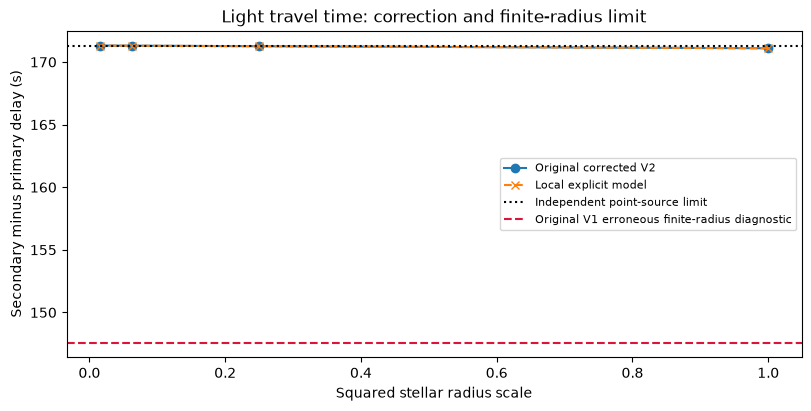

In [3]:
control=np.load(ROOT/'test/fixtures/lighttime_controls.npz',allow_pickle=False)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
x=control['input_radius_scales']**2
ax.plot(x,control['output_original_v2_delay'],'o-',label='Original corrected V2')
ax.plot(x,control['output_local_delay'],'x--',label='Local explicit model')
ax.axhline(float(control['output_point_source_delay']),color='k',ls=':',label='Independent point-source limit')
ax.axhline(float(control['output_original_v1_delay']),color='crimson',ls='--',label='Original V1 erroneous finite-radius diagnostic')
ax.set(xlabel='Squared stellar radius scale',ylabel='Secondary minus primary delay (s)',title='Light travel time: correction and finite-radius limit');ax.legend(fontsize=8)
show(fig)


## 4. Method

For each group $g$, eliminate its zero point $z_g$ before combining the likelihood:

$$z_g=\frac{\sum_{j\in g}\sigma_j^{-2}(y_j-m_j)}{\sum_{j\in g}\sigma_j^{-2}},\qquad
Q=\sum_g\sum_{j\in g}\frac{(y_j-m_j-z_g)^2}{\sigma_j^2},\qquad \log L=-Q/2.$$

Here $y_j$ are measured magnitudes or velocities, $m_j$ are corresponding predictions, and $\sigma_j$ are the declared adjusted uncertainties. Sampling is uniform in the seven coordinates within the detached physical domain, with no extra Gaussian eccentricity prior.

The initializer uses only raw RV fits and photometric depth estimates, followed by generic joint least squares. Historical source initialization and posterior parameters are not inputs. The explicit ensemble sampler retains **50 walkers, 1000 updates, and 500 discarded updates**. For a complementary walker $x_b$, propose $x'=x_b+z(x-x_b)$ with $z=(1+U)^2/2$, $U$ uniform on $[0,1)$, and acceptance $\min(1,z^6L(x')/L(x))$. Two complementary subensembles preserve detailed balance. The standard result is a coordinatewise median of the retained chain, not a best-fit parameter vector.

The next cell actively runs this full reconstruction; it does not load a cached fresh chain.

In [4]:
start=time.perf_counter()
fresh=solve(groups,progress=lambda n,a:print(f'Completed {n}/1000 updates; mean acceptance {a:.3f}',flush=True))
fresh_seconds=time.perf_counter()-start
point=fresh['parameters'];chain=fresh['chain'];fresh_chi=fresh['chi_squared']
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=point[None,:])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_active_notebook.npz',parameters=point,chain=chain,acceptance=fresh['acceptance'],chi_squared=fresh_chi,offsets=fresh['offsets'],prediction=fresh['prediction'])
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,text=True,encoding='utf-8',capture_output=True)
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
assert judged.returncode==0,report
display(Markdown(f'Fresh complete reconstruction: **{fresh_seconds:.2f} s**, Judge **{report["status"]}**, total chi-square **{report["metrics"]["total_chi_squared"]:.6f}**.'))


Completed 100/1000 updates; mean acceptance 0.481


Completed 200/1000 updates; mean acceptance 0.485


Completed 300/1000 updates; mean acceptance 0.489


Completed 400/1000 updates; mean acceptance 0.488


Completed 500/1000 updates; mean acceptance 0.486


...

Completed 700/1000 updates; mean acceptance 0.486


Completed 800/1000 updates; mean acceptance 0.486


Completed 900/1000 updates; mean acceptance 0.487


Completed 1000/1000 updates; mean acceptance 0.487


Fresh complete reconstruction: **618.12 s**, Judge **pass**, total chi-square **15886.850281**.

## 5. Results and comparisons

Original V2 means the actual complete corrected upstream run on these same observations. Fresh means the active local calculation above. Both use the same conditional model and full sampling budget. Posterior intervals below are empirical retained-chain quantiles; they are not independently validated coverage intervals.

| Parameter | Unit | Original V2 median | Fresh median | Fresh 16–84% quantiles |
| --- | --- | ---: | ---: | --- |
| r1 | relative semimajor axis | 0.053189509 | 0.053215717 | 0.052818976 to 0.053653989 |
| r2 | relative semimajor axis | 0.007816559 | 0.0078177906 | 0.0077429134 to 0.007901487 |
| inclination (deg) | degree | 89.095149 | 89.09292 | 89.043566 to 89.137949 |
| sqrt(e) sin(omega) | dimensionless | -0.54978897 | -0.54967024 | -0.5503555 to -0.54897897 |
| sqrt(e) cos(omega) | dimensionless | 0.085515841 | 0.085545136 | 0.085349744 to 0.085739463 |
| mean disk S_J | dimensionless | 0.34647303 | 0.34621644 | 0.33815793 to 0.35434022 |
| K1 (km/s) | km/s | 15.864138 | 15.86405 | 15.846982 to 15.88139 |

| Group | Original V2 chi-square | Fresh chi-square |
| --- | ---: | ---: |
| WASP | 7992.439540 | 7992.647912 |
| NITES | 3668.086132 | 3665.645437 |
| OED | 250.049690 | 250.476331 |
| BYU | 2250.186061 | 2251.923685 |
| KPNO | 1706.147995 | 1706.305970 |
| RV | 19.933811 | 19.850946 |
| Total | 15886.843229 | 15886.850281 |

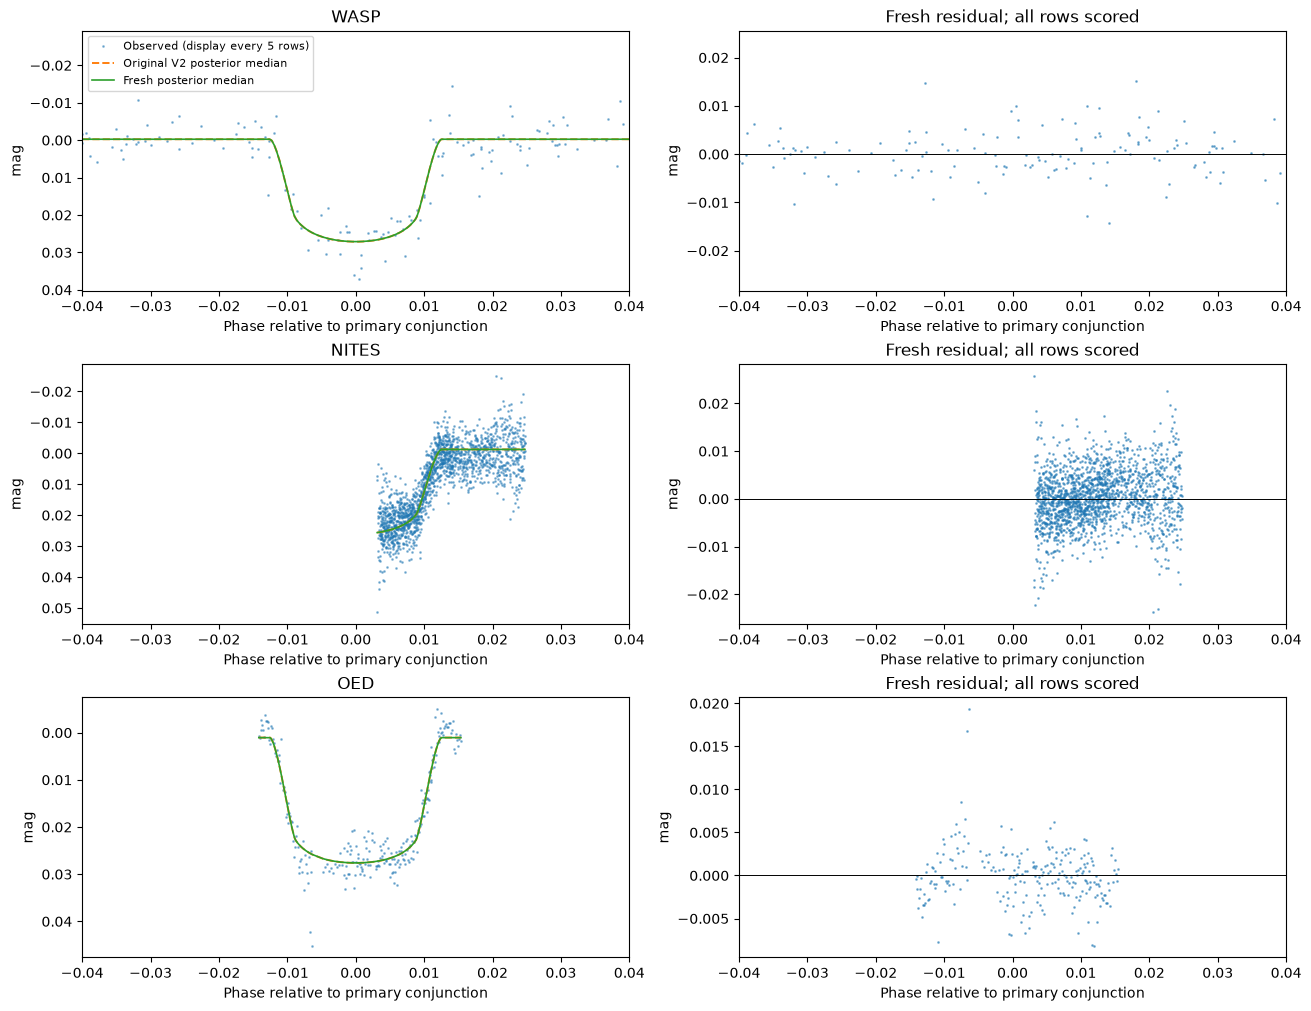

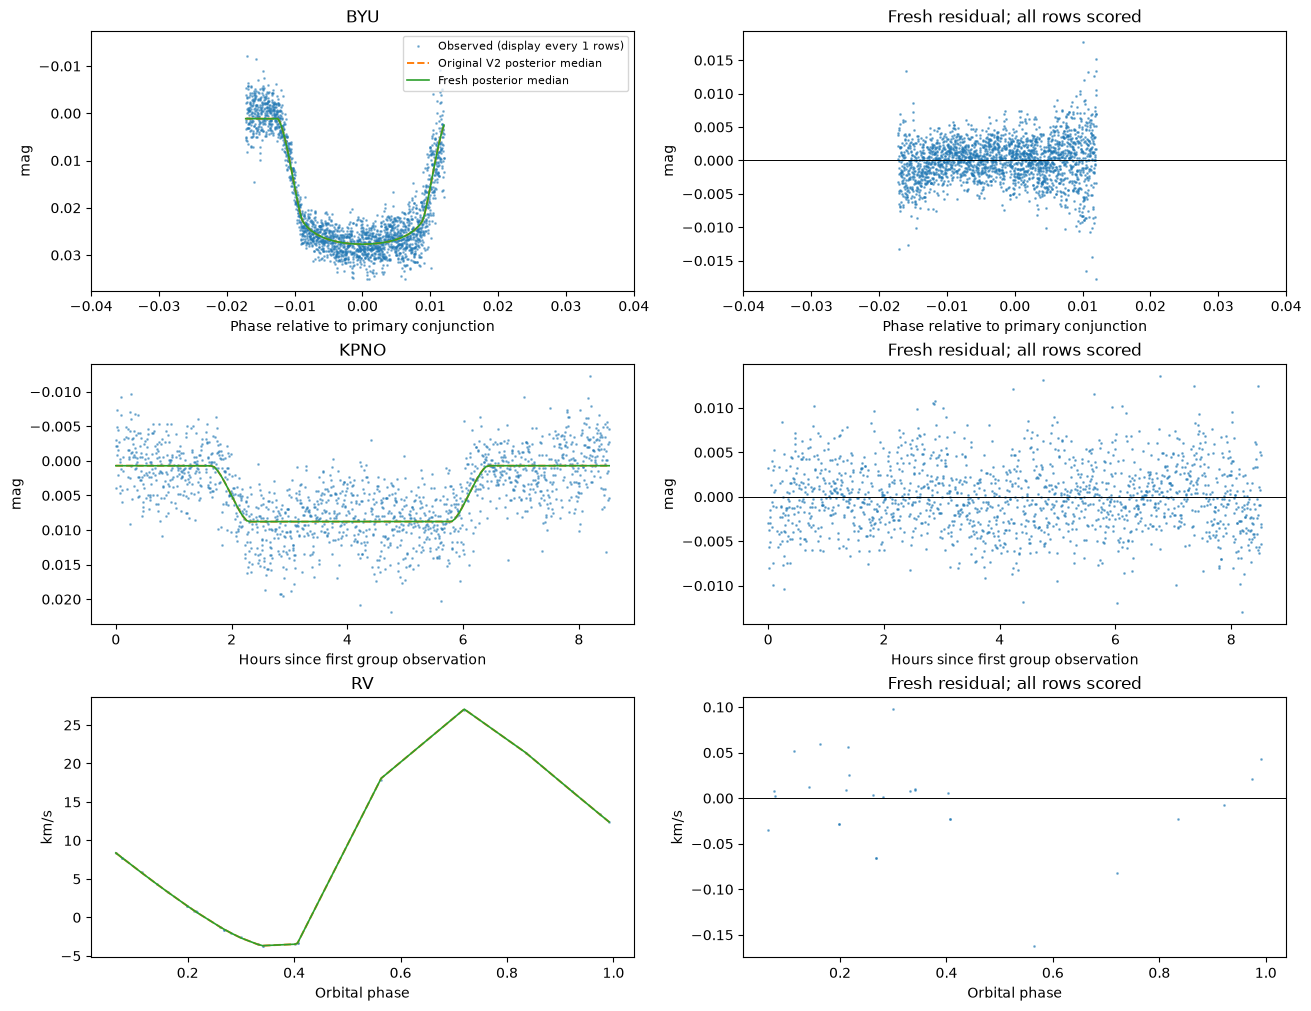

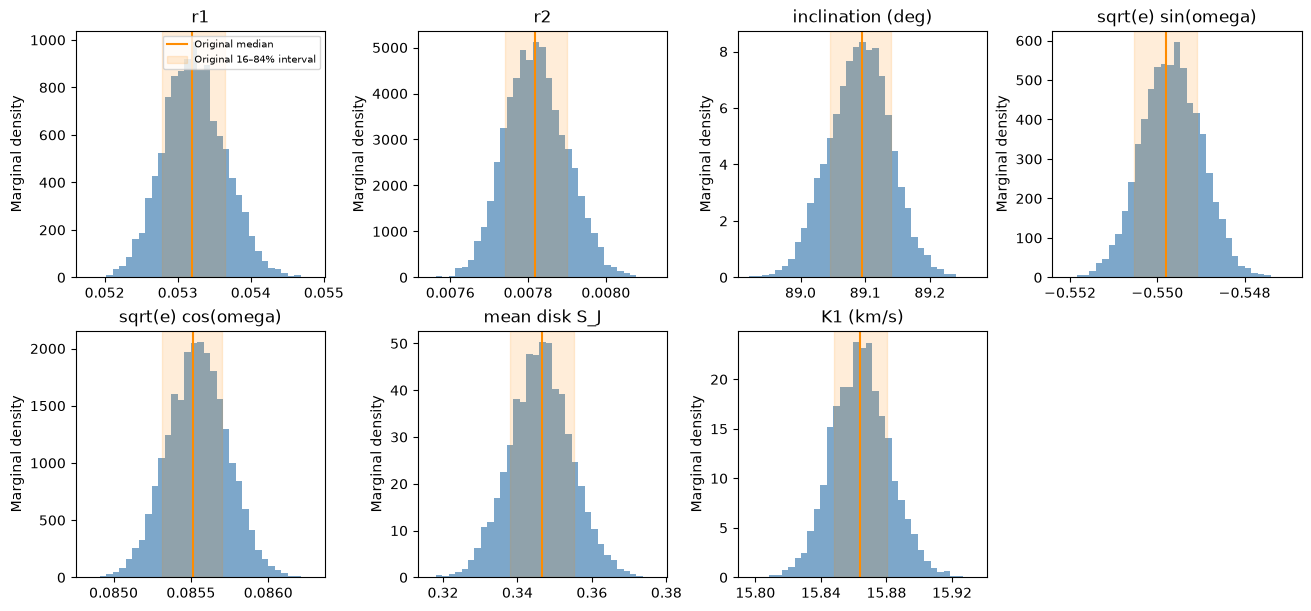

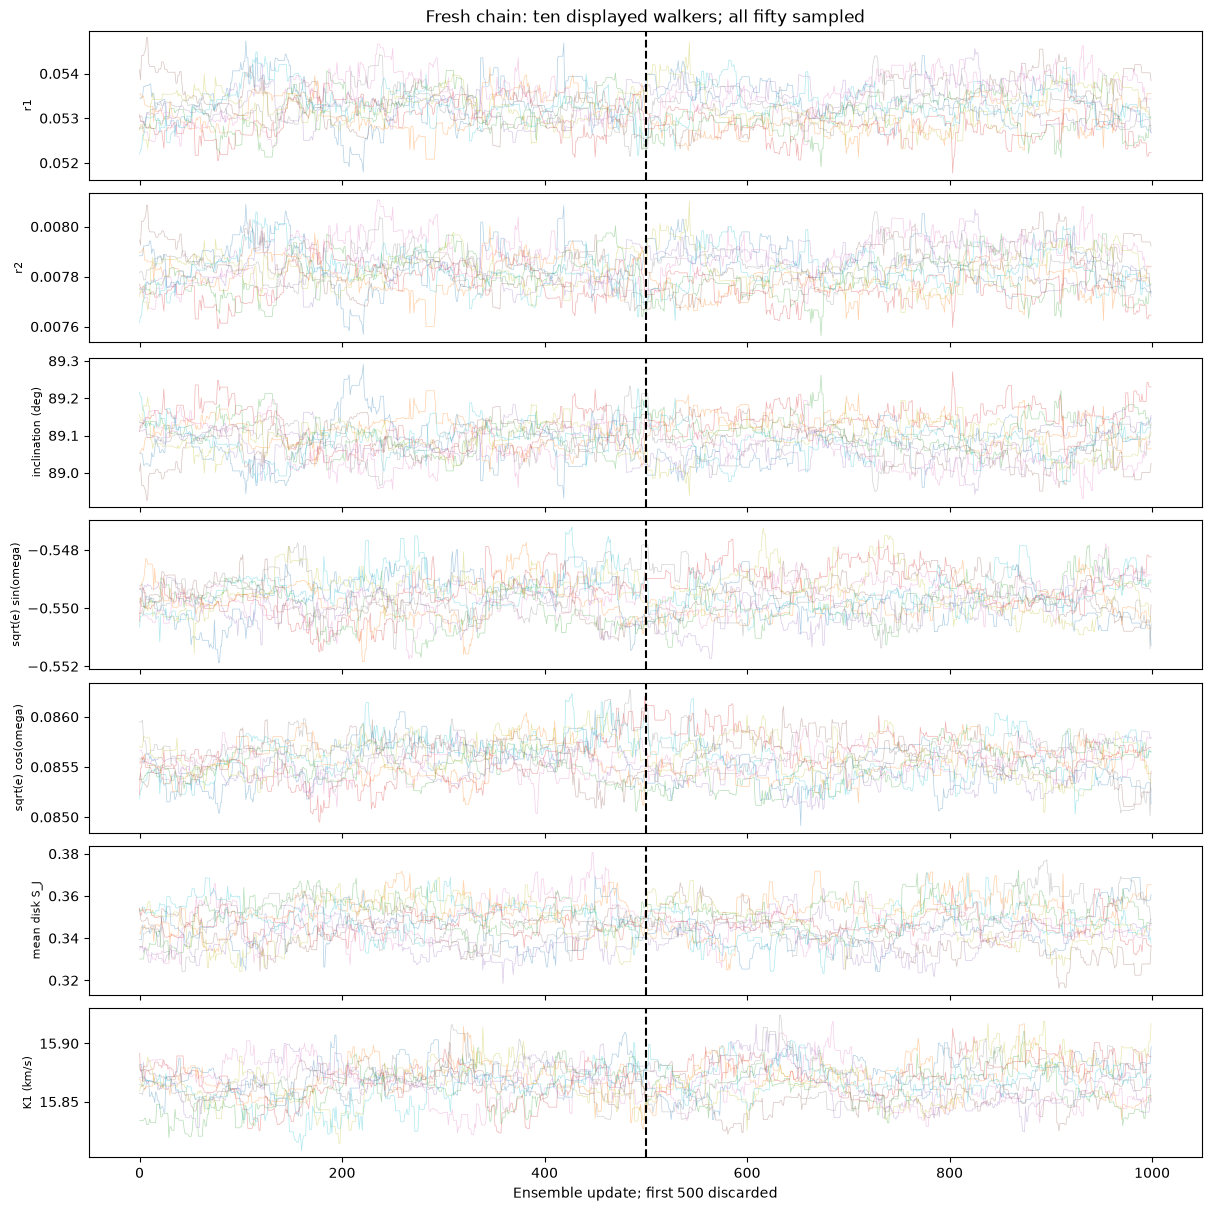

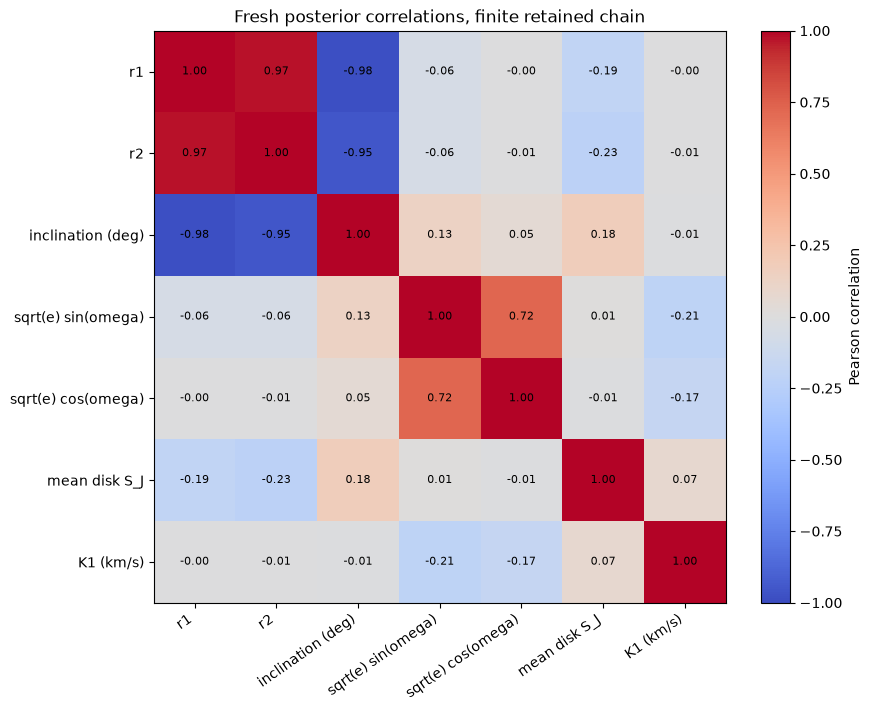

In [5]:
q=np.quantile(chain[:,500:].reshape(-1,7),[.16,.5,.84],axis=0)
units=['relative semimajor axis','relative semimajor axis','degree','dimensionless','dimensionless','dimensionless','km/s']
table=['| Parameter | Unit | Original V2 median | Fresh median | Fresh 16–84% quantiles |','| --- | --- | ---: | ---: | --- |']
for j,name in enumerate(viz.PARAMETERS):table.append(f'| {name} | {units[j]} | {source_point[j]:.8g} | {point[j]:.8g} | {q[0,j]:.8g} to {q[2,j]:.8g} |')
display(Markdown('\n'.join(table)))
source_chi=residuals(source_point,groups,True)[0]
metrics=['| Group | Original V2 chi-square | Fresh chi-square |','| --- | ---: | ---: |']
for name,a,b in zip(viz.NAMES,source_chi,fresh_chi):metrics.append(f'| {name} | {a:.6f} | {b:.6f} |')
metrics.append(f'| Total | {source_chi.sum():.6f} | {fresh_chi.sum():.6f} |')
display(Markdown('\n'.join(metrics)))
show(viz.group_fits(groups,point,source_point,0))
show(viz.group_fits(groups,point,source_point,3))
show(viz.posterior_panels(chain,source['posterior_quantiles']))
show(viz.traces(chain))
show(viz.correlations(chain))


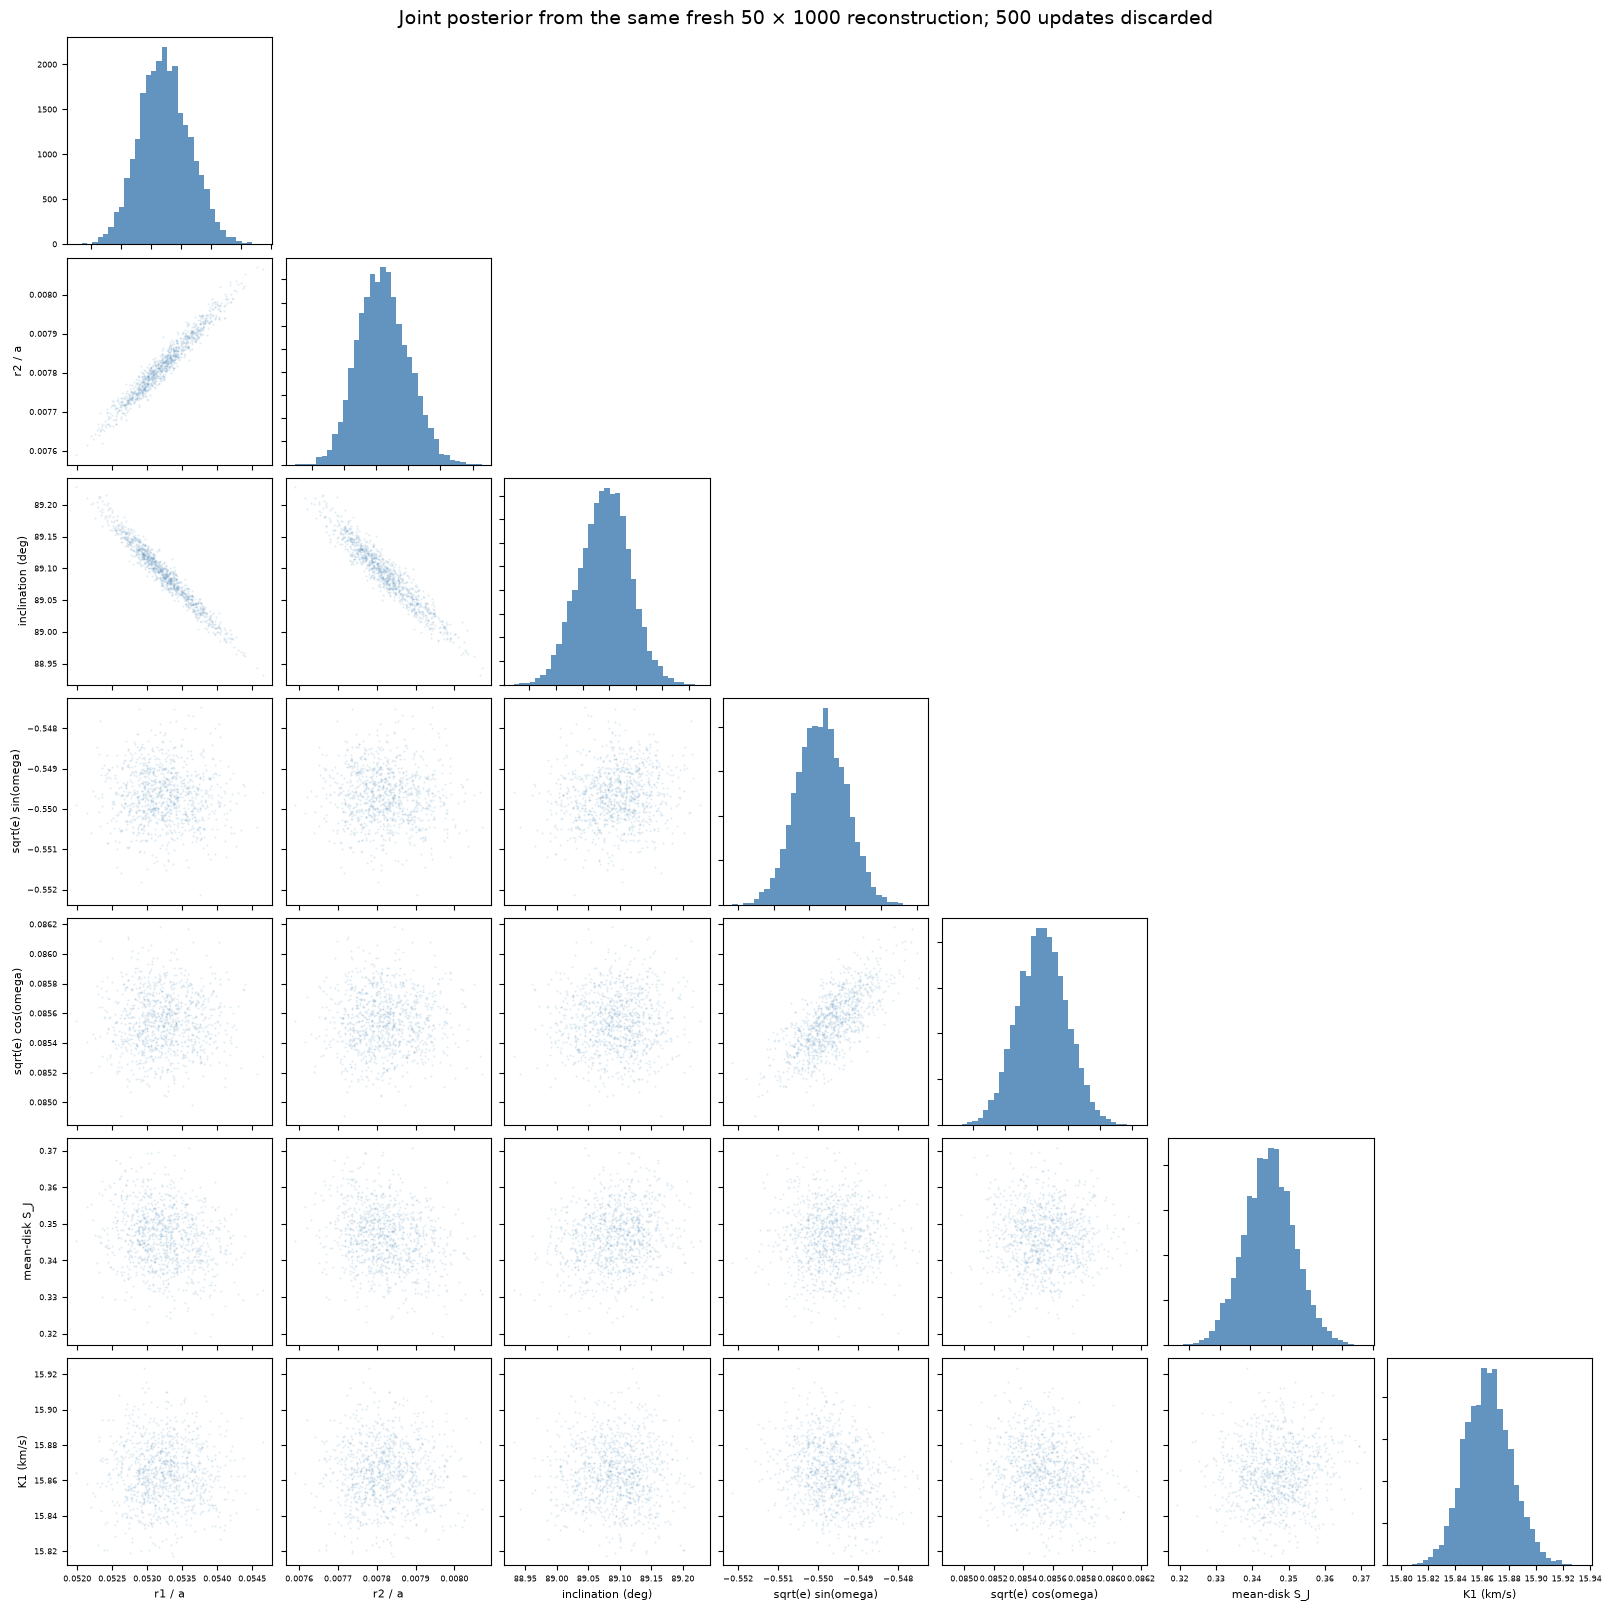

In [6]:
# Pairwise scientific comparison corresponding to the original posterior figure.
# This is the chain actively computed earlier in this same complete execution.
samples=chain[:,500:].reshape(-1,7);display_samples=samples[::25]
labels=['r1 / a','r2 / a','inclination (deg)','sqrt(e) sin(omega)','sqrt(e) cos(omega)','mean-disk S_J','K1 (km/s)']
fig,axes=plt.subplots(7,7,figsize=(16,16),layout='constrained')
for row in range(7):
    for col in range(7):
        ax=axes[row,col]
        if row<col:ax.axis('off');continue
        if row==col:ax.hist(samples[:,col],bins=35,color='steelblue',alpha=.85)
        else:ax.plot(display_samples[:,col],display_samples[:,row],'.',ms=1,alpha=.16,color='steelblue',rasterized=True)
        if row==6:ax.set_xlabel(labels[col],fontsize=8)
        else:ax.tick_params(labelbottom=False)
        if col==0 and row>0:ax.set_ylabel(labels[row],fontsize=8)
        elif col>0:ax.tick_params(labelleft=False)
        ax.tick_params(labelsize=6)
fig.suptitle('Joint posterior from the same fresh 50 × 1000 reconstruction; 500 updates discarded',fontsize=14)
show(fig)


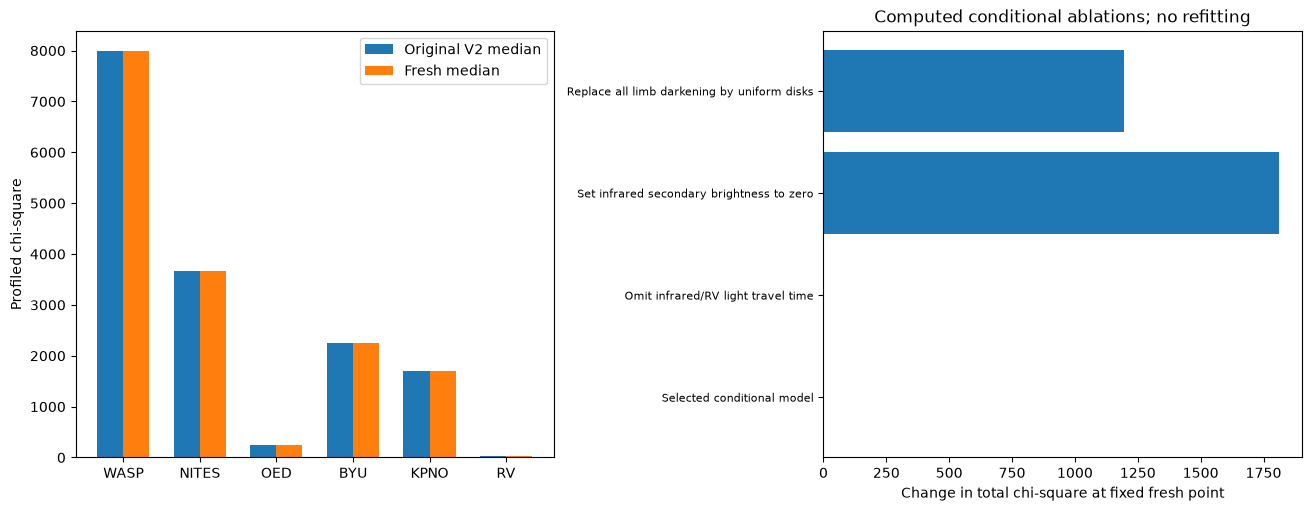

| Fixed-point model | Total chi-square | Change from selected model |
| --- | ---: | ---: |
| Selected conditional model | 15886.850281 | +0.000000 |
| Omit infrared/RV light travel time | 15888.608773 | +1.758492 |
| Set infrared secondary brightness to zero | 17697.977489 | +1811.127208 |
| Replace all limb darkening by uniform disks | 17082.929963 | +1196.079682 |

Mean fresh acceptance **0.4867**, walker range **0.4400–0.5290**. Retained 50-update block-median chi-square range **15886.884555–15887.167745**. The original full run reported median acceptance 0.4765 (range 0.450–0.511) and warned that 1000 updates are shorter than 50 correlation times. This review retains that limitation.

In [7]:
ablations=viz.fixed_point_ablations(point,groups)
show(viz.quality_figure(source_chi,fresh_chi,ablations))
tab=['| Fixed-point model | Total chi-square | Change from selected model |','| --- | ---: | ---: |']
base=list(ablations.values())[0].sum()
for name,v in ablations.items():tab.append(f'| {name} | {v.sum():.6f} | {v.sum()-base:+.6f} |')
display(Markdown('\n'.join(tab)))
accept=fresh['acceptance']
block_points=np.array([np.median(chain[:,a:a+50].reshape(-1,7),axis=0) for a in range(500,1000,50)])
block_chi=np.array([residuals(p,groups,True)[0].sum() for p in block_points])
display(Markdown(f'Mean fresh acceptance **{accept.mean():.4f}**, walker range **{accept.min():.4f}–{accept.max():.4f}**. Retained 50-update block-median chi-square range **{block_chi.min():.6f}–{block_chi.max():.6f}**. The original full run reported median acceptance 0.4765 (range 0.450–0.511) and warned that 1000 updates are shorter than 50 correlation times. This review retains that limitation.'))


The ablations recompute forward predictions at the same fresh parameter point. They isolate changed physical assumptions but do not claim optimized evidence ratios or parameter uncertainty. The next diagnostic adds independent noise at the declared uncertainty scale and performs a local refit, paired with an equal-budget refit of the unperturbed data. These are actual computed robustness diagnostics, not additional full posterior runs.

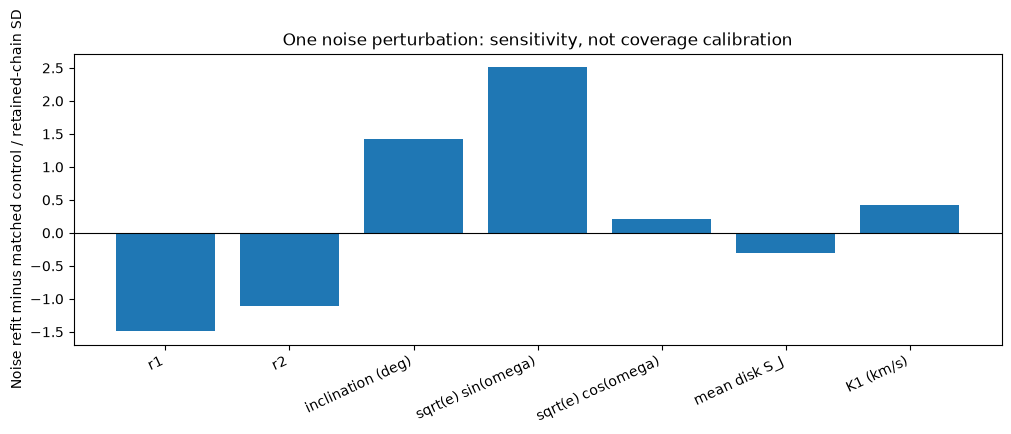

Paired diagnostic refits took **1.51 s**. Original-data chi-square: matched control **15886.810757**, noise refit **15905.409784**.

799

In [8]:
from scipy.optimize import least_squares
rng=np.random.default_rng();perturbed=[]
for t,y,s,w,flag in groups:perturbed.append((t,(y+rng.normal(size=len(y))*s).astype(np.float32),s,w,flag))
def local_fit(data):
    def objective(p):return residuals(p,data) if valid(p) else np.full(15488,1e6)
    return least_squares(objective,point,x_scale=[.05,.008,1,.1,.1,.3,15],diff_step=1e-5,max_nfev=100).x
robust_start=time.perf_counter();matched=local_fit(groups);noisy=local_fit(perturbed)
robust_seconds=time.perf_counter()-robust_start
width=np.std(chain[:,500:].reshape(-1,7),axis=0)
shift=(noisy-matched)/width
fig,ax=plt.subplots(figsize=(10,4),layout='constrained');ax.bar(range(7),shift);ax.axhline(0,color='k',lw=.8);ax.set_xticks(range(7),viz.PARAMETERS,rotation=25,ha='right');ax.set(ylabel='Noise refit minus matched control / retained-chain SD',title='One noise perturbation: sensitivity, not coverage calibration');show(fig)
robust={'matched_refit_original_chi_squared':float(residuals(matched,groups,True)[0].sum()),'noise_refit_original_chi_squared':float(residuals(noisy,groups,True)[0].sum()),'seconds':robust_seconds,'shift_over_chain_SD':shift.tolist()}
display(Markdown(f'Paired diagnostic refits took **{robust_seconds:.2f} s**. Original-data chi-square: matched control **{robust["matched_refit_original_chi_squared"]:.6f}**, noise refit **{robust["noise_refit_original_chi_squared"]:.6f}**.'))
(ROOT/'notebooks/reference_outputs/fresh_notebook_metrics.json').write_text(json.dumps({'full_seconds':fresh_seconds,'total_chi_squared':float(fresh_chi.sum()),'acceptance_mean':float(accept.mean()),'block_chi_squared':block_chi.tolist(),'robustness':robust,'figure_count':len(figures)},indent=2),encoding='utf8')


### Historical comparison in the selected paper

The following are published Table 1 values, retained as historical context. They are **not** measurements from the current source or local run, and the 2014 Wilson–Devinney/PHOEBE analysis is not rerun here. The current seven-coordinate original/fresh table above supplies the actual reproduced comparison. Published secondary depth uses the proxy S_J (r2/r1)^2, rather than asserting an independently measured brightness truth.

| Quantity | Unit | Published ellc (2016) | Published GMC (2014) |
| --- | --- | --- | --- |
| Primary fractional radius | relative semimajor axis | 0.0533 ± 0.0004 | 0.0534 ± 0.0021 |
| Secondary fractional radius | relative semimajor axis | 0.00783 ± 0.00008 | 0.0081 ± 0.0004 |
| Inclination | degree | 89.09 ± 0.05 | 89.08 ± 0.04 |
| Eccentricity | dimensionless | 0.3096 ± 0.0007 | 0.3098 ± 0.0005 |
| Argument of periastron | degree | 278.9 ± 0.03 | 278.85 ± 1.29 |
| Secondary depth proxy | relative flux | 0.00749 ± 0.00018 | 0.00737 ± 0.00024 |
| Velocity scale | km/s | 15.87 ± 0.02 | 15.84 ± 0.01 |

The full pairwise posterior triangle above uses **this same actively computed fresh chain**. It preserves nonlinear joint geometry beyond the correlation heatmap. Diagonal histograms use every retained sample; pairwise scatter is thinned only for display. The plot is not a calibrated true-parameter coverage region. The original V1 horizontal line in the physics figure is an explicitly rounded historical diagnostic (147.5877 s); the full source precision remains archived.


## 6. Conclusion

The fresh seven-parameter result is judged through all six complete observation groups. The declared boundary allows physical parameter tradeoffs rather than requiring the original finite-chain median. The quality increment is transparent and conditional; it is not a 95% true-parameter region or a Wilks result at a proven maximum likelihood point.

Source and local deterministic stages agree independently of stochastic chain summaries. Light travel time converges to the analytic point-source limit after the identified V2 correction. Sparse limb-darkening quadrature remains an approximation. Fixed mass ratio, band-dependent limb darkening, omission of optical light time, numerical interpolation, a single RV zero point across instruments, noise assumptions, and limited chain length constrain scientific interpretation. A lower chi-square after a local refit can reflect finite sampling or optimizer basin differences; it is not evidence that added noise improves physical accuracy. No independent stellar-property ground truth or verified posterior coverage is claimed.